<a href="https://colab.research.google.com/github/vigneshwaranmanikandan/data-science/blob/main/Matplotlib_Tasks(Netflix%20dataset).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
df = pd.read_csv("/content/netflix_titles.csv")
print(df)

     show_id     type                  title         director  \
0         s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1         s2  TV Show          Blood & Water              NaN   
2         s3  TV Show              Ganglands  Julien Leclercq   
3         s4  TV Show  Jailbirds New Orleans              NaN   
4         s5  TV Show           Kota Factory              NaN   
...      ...      ...                    ...              ...   
8802   s8803    Movie                 Zodiac    David Fincher   
8803   s8804  TV Show            Zombie Dumb              NaN   
8804   s8805    Movie             Zombieland  Ruben Fleischer   
8805   s8806    Movie                   Zoom     Peter Hewitt   
8806   s8807    Movie                 Zubaan      Mozez Singh   

                                                   cast        country  \
0                                                   NaN  United States   
1     Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa 

In [4]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [9]:
df['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


In [17]:
!pip install mplcursors

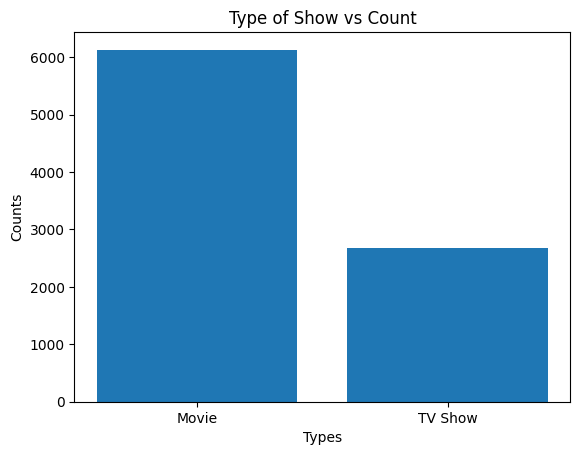

In [22]:
#1)Display the total number of Movies and TV Shows using a bar chart.
import matplotlib.pyplot as plt
import mplcursors

types = df['type'].value_counts()

bars = plt.bar(types.index, types.values)

plt.xlabel('Types')
plt.ylabel('Counts')
plt.title('Type of Show vs Count')

cursor = mplcursors.cursor(bars, hover=True)

@cursor.connect("add")
def on_hover(sel):
    sel.annotation.set_text(
        f"{types.index[sel.index]}\nCount: {types.values[sel.index]}")

plt.show()

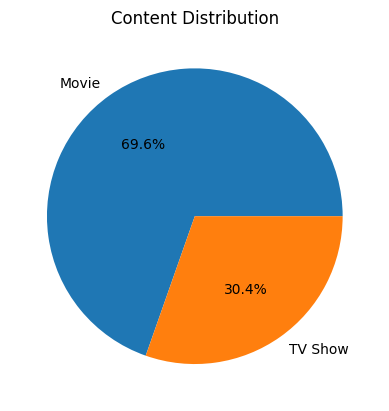

In [23]:
#2)Create a pie chart showing content percentages.
content = df['type'].value_counts()

pie = plt.pie(content.values, labels=content.index, autopct='%1.1f%%')
plt.title('Content Distribution')
plt.show()

In [33]:
print(df['duration'])
movies = df[df['type'] == 'Movie'].copy()
movies['duration_num'] = movies['duration'].str.extract(r'(\d+)').astype(float)
movies = movies.dropna(subset=['duration_num'])

0          90 min
1       2 Seasons
2        1 Season
3        1 Season
4       2 Seasons
          ...    
8802      158 min
8803    2 Seasons
8804       88 min
8805       88 min
8806      111 min
Name: duration, Length: 8807, dtype: object


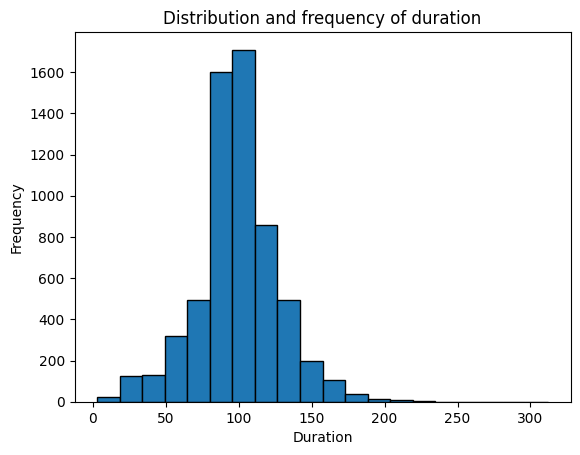

In [36]:
#3)Create a histogram for movie durations.
duration = movies['duration_num']
plt.hist(duration, bins=20, edgecolor='black')
plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.title('Distribution and frequency of duration')
plt.show()

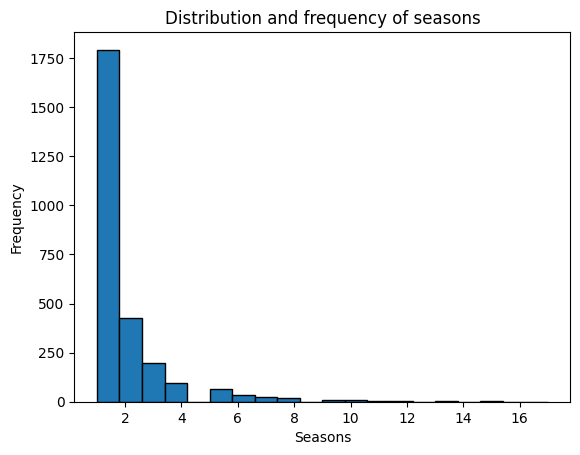

In [37]:
tv = df[df['type'] == 'TV Show'].copy()
tv['seasons'] = tv['duration'].str.extract(r'(\d+)').astype(float)
tv = tv.dropna(subset=['seasons'])

plt.hist(tv['seasons'], bins=20, edgecolor='black')
plt.xlabel('Seasons')
plt.ylabel('Frequency')
plt.title('Distribution and frequency of seasons')
plt.show()

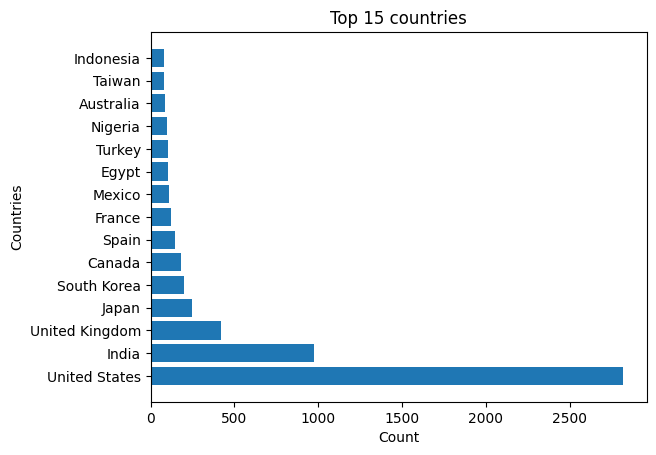

In [39]:
#4)Display the top 15 countries using a horizontal bar chart.
countries = df['country'].value_counts().head(15)

plt.barh(countries.index, countries.values)
plt.xlabel('Count')
plt.ylabel('Countries')
plt.title('Top 15 countries')
plt.show()

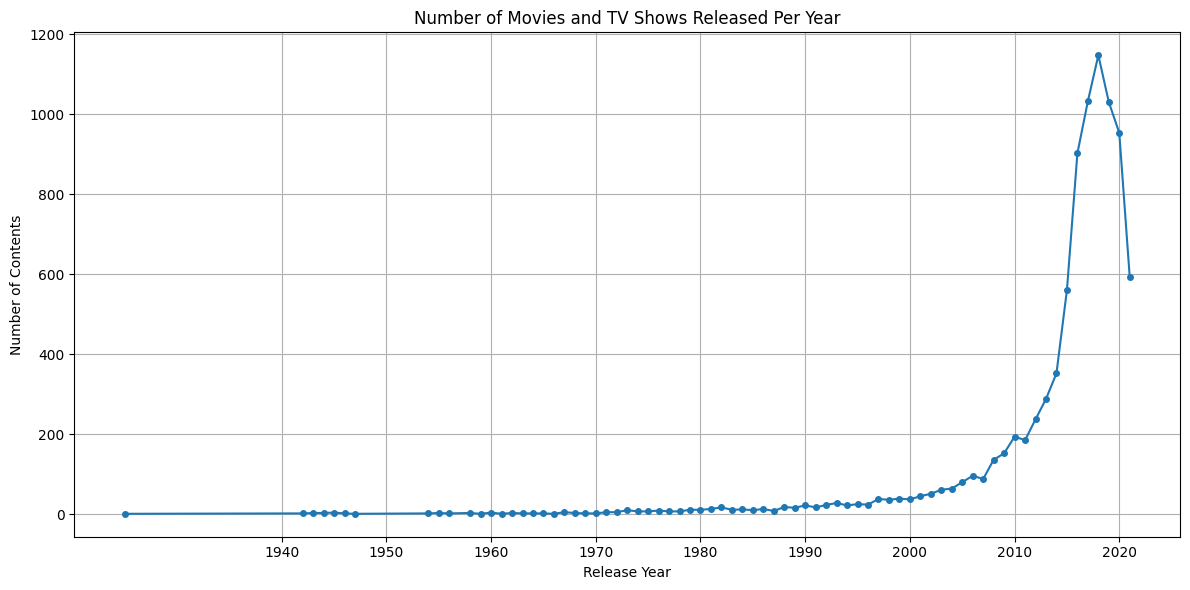

In [46]:
#5)Create a line chart showing content released per year.
year = df['release_year'].value_counts().sort_index()
plt.figure(figsize=(12, 6))
plt.plot(year.index, year.values, marker='o', markersize=4)
plt.xlabel('Release Year')
plt.ylabel('Number of Contents')
plt.title('Number of Movies and TV Shows Released Per Year')
plt.grid(True)
plt.xticks(range(1940, 2026, 10))
plt.tight_layout()

plt.show()

Text(0, 0.5, 'Count')

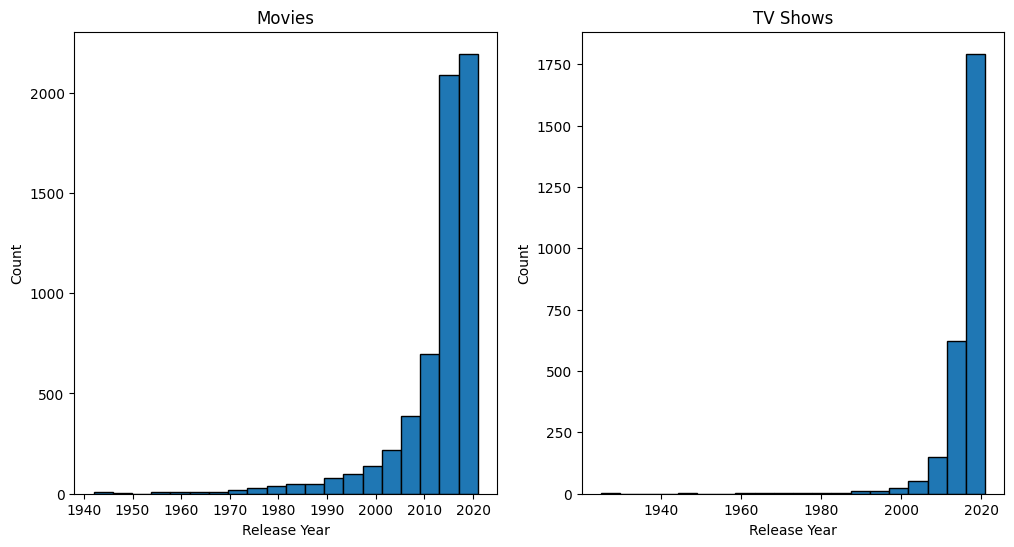

In [49]:
#6)Compare Movies and TV Shows using two subplots.
movies = df[df['type'] == 'Movie']
tv = df[df['type'] == 'TV Show']

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.hist(movies['release_year'],bins=20, edgecolor='black')
plt.title('Movies')
plt.xlabel('Release Year')
plt.ylabel('Count')

plt.subplot(1,2,2)
plt.hist(tv['release_year'],bins=20, edgecolor='black')
plt.title('TV Shows')
plt.xlabel('Release Year')
plt.ylabel('Count')



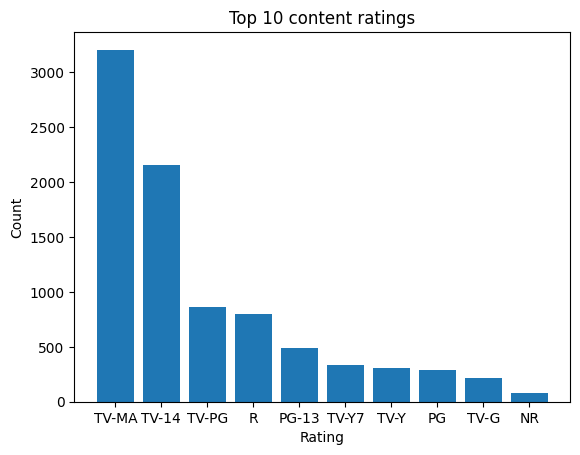

In [54]:
#7)Find the top 10 most common content ratings and visualize them.
top_ratings = df['rating'].value_counts().head(10)
plt.bar(top_ratings.index, top_ratings.values)
plt.title('Top 10 content ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

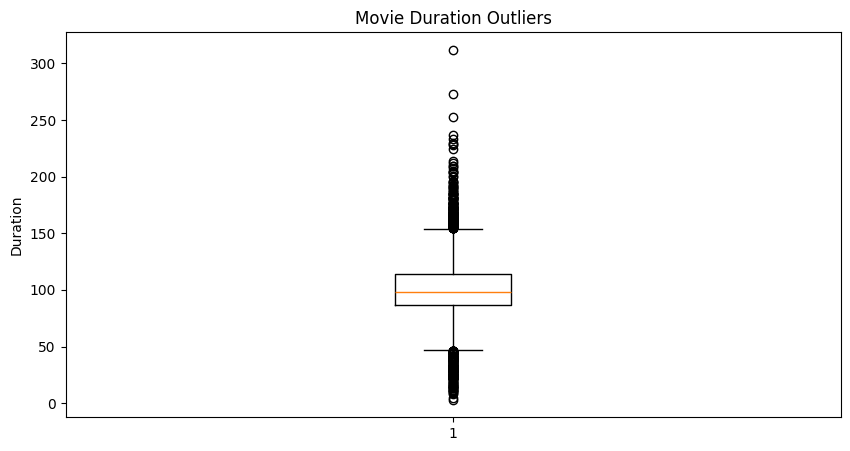

In [61]:
#8)Create a box plot to identify movie duration outliers.
movies = df[df['type'] == 'Movie']
duration = movies['duration'].str.extract(r'(\d+)').astype(float)
duration = duration.dropna()
plt.figure(figsize=(10, 5))
plt.boxplot(duration[0])
plt.title('Movie Duration Outliers')
plt.ylabel('Duration')
plt.show()

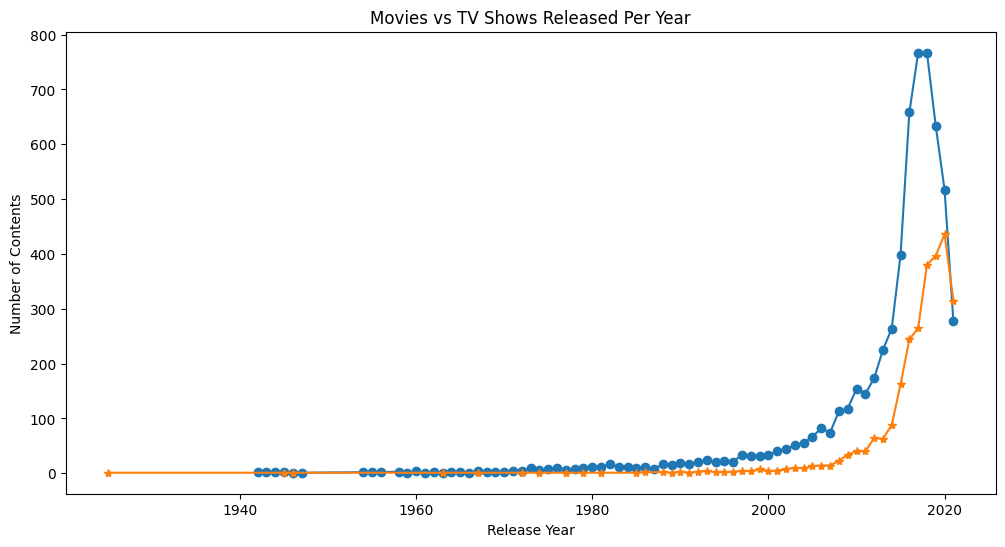

In [65]:
#9)Compare the number of Movies and TV Shows released each year using two lines.
movies = df[df['type'] == 'Movie']
tv = df[df['type'] == 'TV Show']
movie_year = movies['release_year'].value_counts().sort_index()
tv_year = tv['release_year'].value_counts().sort_index()
plt.figure(figsize=(12, 6))

plt.plot(movie_year.index, movie_year.values, label='Movies', marker='o')
plt.plot(tv_year.index, tv_year.values, label='TV Shows', marker='*')
plt.xlabel('Release Year')
plt.ylabel('Number of Contents')
plt.title('Movies vs TV Shows Released Per Year')
plt.show()